<a href="https://colab.research.google.com/github/ShubhGuPTA-cmd/ML-experiments/blob/main/Cart_and_ensemble_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

In [ ]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Shape:", X.shape)
print("Target Classes:", data.target_names)

Dataset Shape: (569, 30)
Target Classes: ['malignant' 'benign']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (455, 30)
Testing Data: (114, 30)


In [ ]:
cart_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

cart_model.fit(X_train, y_train)

print("CART Model Trained Successfully")

CART Model Trained Successfully


In [ ]:
y_pred = cart_model.predict(X_test)

print("Predicted Values:")
print(y_pred)

print("Actual Values:")
print(y_test)

Predicted Values:
[1 0 0 1 1 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0
 1 0 1 1 0 1 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 0 1 1 0 0 1 1 1 0 0 1 1 0 0 1 0
 1 1 1 1 1 1 0 1 1 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1 0 0 1 1 1 0 0 1 0
 1 1 0]
Actual Values:
[1 0 0 1 1 0 0 0 1 1 1 0 1 0 1 0 1 1 1 0 0 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0
 1 0 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 0 0 1 1 1 0 0 1 1 0 0 1 0
 1 1 1 0 1 1 0 1 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1 0 0 1 1 1 0 1 1 0
 1 1 0]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 94.73684210526315 %

Confusion Matrix:
[[40  3]
 [ 3 68]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        43
           1       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



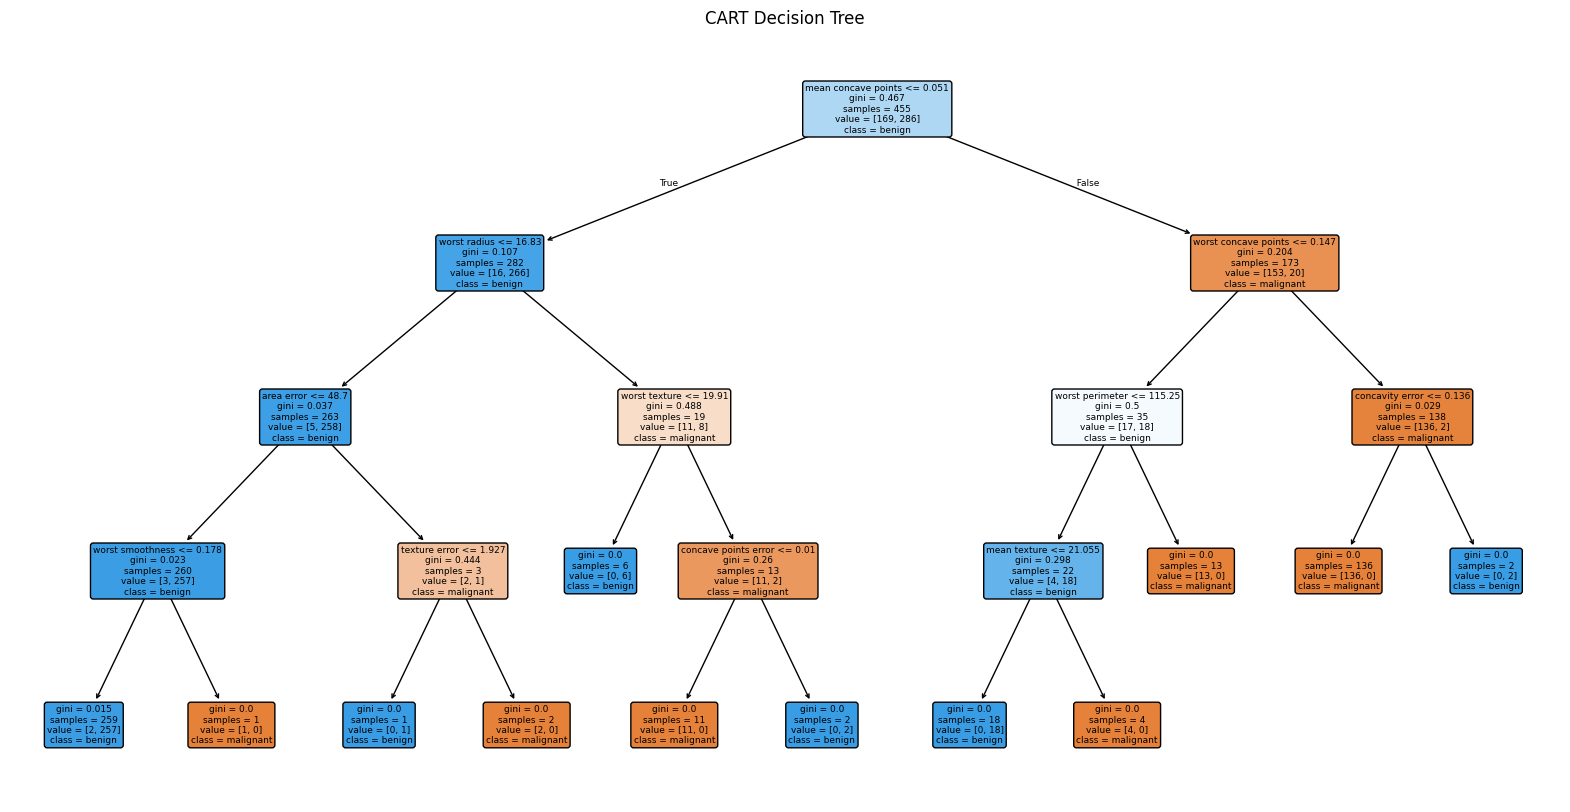

In [ ]:
plt.figure(figsize=(20, 10))

plot_tree(
    cart_model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True
)

plt.title("CART Decision Tree")
plt.show()

In [ ]:
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [ ]:
models = {
    "Bagging": BaggingClassifier(
        n_estimators=50,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=50,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
}

In [ ]:
results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy * 100

    print(name)
    print("Accuracy:", accuracy * 100, "%")
    print("--------------------------")

Bagging
Accuracy: 95.6140350877193 %
--------------------------
Random Forest
Accuracy: 96.49122807017544 %
--------------------------
AdaBoost
Accuracy: 96.49122807017544 %
--------------------------
Gradient Boosting
Accuracy: 95.6140350877193 %
--------------------------


In [ ]:
results_df = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Accuracy"]
)

print(results_df)

               Model   Accuracy
0            Bagging  95.614035
1      Random Forest  96.491228
2           AdaBoost  96.491228
3  Gradient Boosting  95.614035


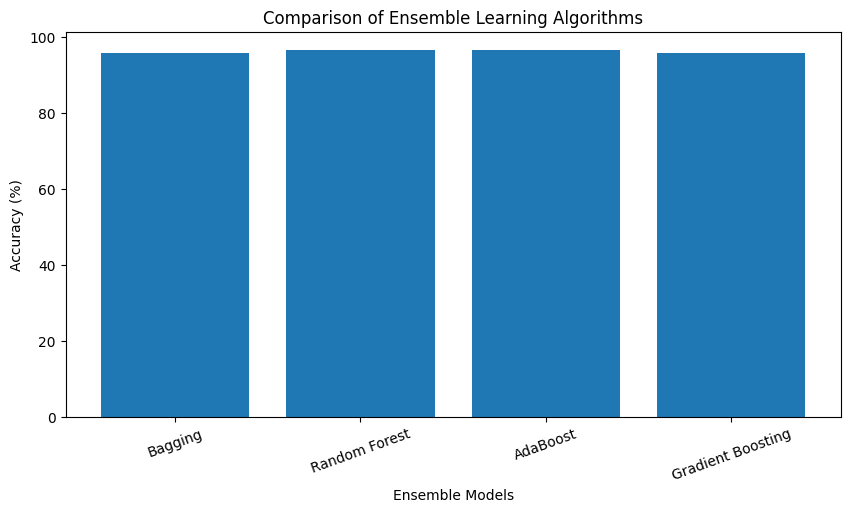

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.xlabel("Ensemble Models")
plt.ylabel("Accuracy (%)")
plt.title("Comparison of Ensemble Learning Algorithms")

plt.xticks(rotation=20)
plt.show()

In [ ]:
voting_model = VotingClassifier(
    estimators=[
        ("dt", DecisionTreeClassifier(max_depth=4)),
        ("rf", RandomForestClassifier(n_estimators=100)),
        ("gb", GradientBoostingClassifier())
    ],
    voting="hard"
)

voting_model.fit(X_train, y_train)

voting_pred = voting_model.predict(X_test)

print("Voting Classifier Accuracy:",
      accuracy_score(y_test, voting_pred) * 100, "%")

Voting Classifier Accuracy: 95.6140350877193 %
